In [1]:
import pennylane as qml
from pennylane import numpy as np
import jax
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt
import os

In [5]:
print(qml.version())

0.44.0


ALGUNOS PARAMETROS

In [ ]:
n_qubits = 3    # 3 qubits nos permiten trabajar con 8 puntos en el dominio.
n_shots = 100000
tot_qubits = n_qubits + 1
ancilla_idx = n_qubits
steps = 2300
q_delta = 0.001
rng_seed = 0
N = np.power(2,n_qubits)    # N = 8 puntos.


DEFINICION DEL PROBLEMA

Como ejemplo particular se pretende resolver la EDO  del oscilador armónico:

$y''(x) + \omega x = 0$

Con condiciones de Dirichlet en los extremos

$y_1 = y_N = q$

Para resolver una EDO, se discretiza el dominio (paso h). En este caso, utilizando las expresiones centradas para la primera y segunda derivada, queda:

$y_{i-1} + (-2 + \omega^2 h^2)y_i + y_{i+1} = 0, \quad i = 2, ..., N-1$

Esto da lugar a un sistema lineal, $A \vec{y} = \vec{b}$

donde $\vec{y} = (y_1, y_2, ... , y_N)^T$

In [ ]:
#vector b
b = np.zeros(8)
N = np.power(2,n_qubits)
b[0] = 1
b[N-1] = 1
#matriz A
A = np.zeros((8,8))
x0 = 0
xf = 2
h = -(x0 - xf)/N
omega = 3
q = omega**2 * h**2 - 2

for i in range(1,N-1):
  A[i,i] = q
  A[i,i-1] = 1
  A[i,i+1] = 1
#Condiciones de contorno
A[0,0]=1
A[N-1,N-1]=1
A[N-1,2]=0

Hemos construido A. No obstante, los circuitos cuánticos solo trabajan con matrices que son hermíticas (matrices del tipo $M^\dagger M$), por lo tanto debemos transformar nuestro problema en el siguiente:

$A^\dagger A \vec{y} = A^\dagger \vec{b}$

Estos nuevos elementos se llaman $A_{new}$ y $b_{new}$.

[[ 1.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 1.     -1.4375  1.      0.      0.      0.      0.      0.    ]
 [ 0.      1.     -1.4375  1.      0.      0.      0.      0.    ]
 [ 0.      0.      1.     -1.4375  1.      0.      0.      0.    ]
 [ 0.      0.      0.      1.     -1.4375  1.      0.      0.    ]
 [ 0.      0.      0.      0.      1.     -1.4375  1.      0.    ]
 [ 0.      0.      0.      0.      0.      1.     -1.4375  1.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      1.    ]]
[ 1.          0.38219762 -0.4505908  -1.0299219  -1.0299219  -0.45059085
  0.38219762  1.        ]


<function matplotlib.pyplot.show(close=None, block=None)>

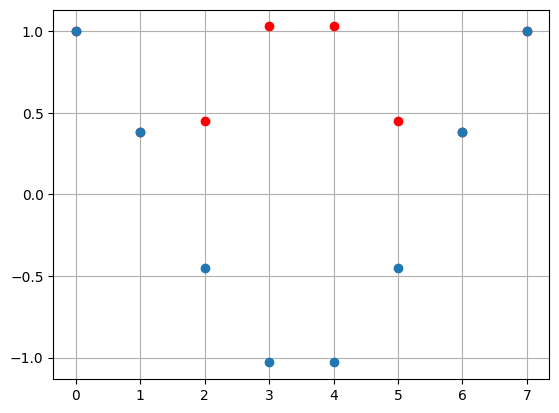

In [12]:

print(A)

normA = np.linalg.norm(A, jnp.inf)
A_scaled = A / normA
b_scaled = b / normA

A_new = A_scaled.conj().T @ A_scaled
b_new = A_scaled.conj().T @ b_scaled

b_new = jnp.array(b_new)
A_new = jnp.array(A_new)


result = jnp.linalg.inv(A) @ b
print(result)
x = range(0,N)
plt.plot(x,abs(result), marker = "o", linestyle="", color="red")
plt.plot(x,result, marker = "o", linestyle="")
plt.grid(linestyle="-")
plt.show

Esta es la solución al problema que nos devuelve un método clásico. Compararemos la solución del algoritmo cuántico con esta.

Codificar un operador lineal en un circuito cuántico se hace concatenando combinaciones de operadores unitarios.

$A_{new} = \sum_{k=1} c_k U_k$

In [9]:
LCU = qml.pauli_decompose(A_new)
#print(f"Descomposición de A en unitarios: \n {LCU}")
c = LCU.coeffs
unitaries = LCU.ops
print(unitaries)
print(c)
H_pauli = qml.Hamiltonian(c, unitaries)
print(len(c))

c:\Users\Eduardo\AppData\Local\Programs\Python\Python313\Lib\site-packages\jax\_src\numpy\array_methods.py:124: UserWarning: Explicitly requested dtype <class 'jax.numpy.complex128'> requested in astype is not available, and will be truncated to dtype complex64. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)


[I(0) @ I(1) @ I(2), I(0) @ I(1) @ X(2), I(0) @ X(1) @ I(2), I(0) @ X(1) @ X(2), I(0) @ Y(1) @ Y(2), I(0) @ Z(1) @ Z(2), X(0) @ X(1) @ I(2), X(0) @ X(1) @ X(2), X(0) @ Y(1) @ Y(2), Y(0) @ X(1) @ Y(2), Y(0) @ Y(1) @ I(2), Y(0) @ Y(1) @ X(2), Z(0) @ I(1) @ Z(2), Z(0) @ Z(1) @ I(2), Z(0) @ Z(1) @ X(2)]
[ 0.27925622 -0.18247934  0.0846281  -0.12165289 -0.12165289 -0.02256198
  0.04231405 -0.06082645  0.06082645 -0.06082645  0.04231405 -0.06082645
 -0.02256199 -0.06487603  0.06082645]
15


Obtenemos una cierta descomposición en unitarios y sus coeficientes asociados.

In [10]:
for i in range(len(c)):
    print(c[i], unitaries[i])

0.27925622 I(0) @ I(1) @ I(2)
-0.18247934 I(0) @ I(1) @ X(2)
0.0846281 I(0) @ X(1) @ I(2)
-0.12165289 I(0) @ X(1) @ X(2)
-0.12165289 I(0) @ Y(1) @ Y(2)
-0.022561982 I(0) @ Z(1) @ Z(2)
0.04231405 X(0) @ X(1) @ I(2)
-0.060826447 X(0) @ X(1) @ X(2)
0.060826447 X(0) @ Y(1) @ Y(2)
-0.060826447 Y(0) @ X(1) @ Y(2)
0.04231405 Y(0) @ Y(1) @ I(2)
-0.060826447 Y(0) @ Y(1) @ X(2)
-0.022561986 Z(0) @ I(1) @ Z(2)
-0.064876035 Z(0) @ Z(1) @ I(2)
0.060826447 Z(0) @ Z(1) @ X(2)


Preparamos b y el ansatz del circuito.

In [ ]:
# Este operador simplemente prepara b mediante amplitude encoding.
from numpy import select
def U_b():
  qml.StatePrep(b_new, wires=range(n_qubits), normalize=True)

#Necesito una funcion que me traduzca XYZ a su versión controlada.

def controlled_ope(expr):
    ops = []
    t = expr.split("@")
    for i in range(n_qubits):
      ope_str = t[i].strip()[0]
      match ope_str:
        case "X":
          ope = qml.PauliX
          #print("X ", i)
        case "Y":
          ope = qml.PauliY
          #print("Y ", i)

        case "Z":
          ope = qml.PauliZ
          #print("Z ", i)

        case "I":
          #print("I ", i)
          continue
      if ope != "I":
        qml.ctrl(op=ope,control=ancilla_idx)(wires=i)

def CA(idx):
  controlled_ope(str(unitaries[idx]))


# Ansatz: circuito que mapea |0> en |x>. Elegimos un ansatz predefinido.
# Es suficientemente complejo como para abarcar un gran dominio de soluciones.
def variational_block(weights):
  qml.StronglyEntanglingLayers(weights=weights, wires = range(n_qubits))


Preparamos $\mu _{l, l', j}$, el circuito que calcula la función de coste local, $C_L$.

In [ ]:
dev_mu = qml.device("lightning.qubit", wires=tot_qubits)

@qml.qnode(dev_mu, interface="jax")
def local_hadamard_test(weights, l=None, lp=None, j=None, part=None):

    # First Hadamard gate applied to the ancillary qubit.
    qml.Hadamard(wires=ancilla_idx)

    # For estimating the imaginary part of the coefficient "mu", we must add a "-i"
    # phase gate.
    if part == "Im" or part == "im":
        qml.PhaseShift(-np.pi / 2, wires=ancilla_idx)

    # Variational circuit generating a guess for the solution vector |x>
    variational_block(weights)

    # Controlled application of the unitary component A_l of the problem matrix A.
    CA(l)

    # Adjoint of the unitary U_b associated to the problem vector |b>.
    # In this specific example Adjoint(U_b) = U_b.
    qml.adjoint(U_b)()

    # Controlled Z operator at position j. If j = -1, apply the identity.
    if j != -1:
        qml.CZ(wires=[ancilla_idx, j])

    # Unitary U_b associated to the problem vector |b>.
    U_b()

    # Controlled application of Adjoint(A_lp).
    # In this specific example Adjoint(A_lp) = A_lp.
    CA(lp)

    # Second Hadamard gate applied to the ancillary qubit.
    qml.Hadamard(wires=ancilla_idx)

    # Expectation value of Z for the ancillary qubit.
    return qml.expval(qml.PauliZ(wires=ancilla_idx))

Para obtener las partes real e imaginaria de $\mu(l, l', j)$, es necesario ejecutar el circuito cuántico anterior tanto con un desplazamiento de fase en el cúbit auxiliar como sin él. Esto se realiza de forma automática mediante la siguiente función: el test de Hadamard.

In [13]:
def mu(weights, l=None, lp=None, j=None):
    """Generates the coefficients to compute the "local" cost function C_L."""

    mu_real = local_hadamard_test(weights, l=l, lp=lp, j=j, part="Re")
    mu_imag = local_hadamard_test(weights, l=l, lp=lp, j=j, part="Im")

    return mu_real + 1.0j * mu_imag

**Función de coste local**

Definamos primero una función para estimar <x|A^t A|x>

In [14]:
def psi_norm(weights):
    """Returns the normalization constant <psi|psi>, where |psi> = A |x>."""
    norm_complex_sum = 0.0 + 0.0j  # Initialize as a complex number

    for l in range(0, len(c)):
        for lp in range(0, len(c)):
            # Each term is c_l * conj(c_lp) * <x| A_l+ A_lp |x>
            term = c[l] * jnp.conj(c[lp]) * mu(weights, l, lp, -1)
            norm_complex_sum = norm_complex_sum + term

    # Take the real part of the total sum for the normalization constant
    return jnp.real(norm_complex_sum)

Por fin podemos definir la función de coste de nuestro problema de minimización. Utilizamos la expresión analítica de C_L en función de los coeficientes mu(l, lp, j) presentados en la introducción.

In [ ]:
def cost_loc(weights):
    """Local version of the cost function. Tends to zero when A|x> is proportional to |b>."""
    numerator_complex_sum = 0.0 + 0.0j

    for l in range(0, len(c)):
        for lp in range(0, len(c)):
            for j in range(0, n_qubits):
                # Each term should be c_l * conj(c_lp) * <x| A_l+ Z_j A_lp |x>
                term = c[l] * jnp.conj(c[lp]) * mu(weights, l, lp, j)
                numerator_complex_sum = numerator_complex_sum + term

    # Take the real part of the total sum for the numerator
    numerator = jnp.real(numerator_complex_sum)
    'print("numerator = ", numerator)'

    # Calculate psi_norm, which now returns the real part of the sum <x|A+A|x>
    norm_psi = psi_norm(weights)

    # Add a small epsilon to the denominator to prevent division by zero or very small numbers
    epsilon = 1e-8
    denominator = n_qubits * norm_psi + epsilon
    'print("denominator = ", denominator)'

    # Cost function C_L
    return 0.5 - 0.5 * numerator / denominator

cost_grad = jax.jit(jax.value_and_grad(cost_loc))



In [16]:
miruta = os.getcwd()
print(miruta)
print(os.listdir())

c:\Users\Eduardo\Documents\_Universidad\_Curso_4\__TFG\Notebooks
['chebyshev.ipynb', 'costes', 'costes_2', 'euler copy 2.ipynb', 'euler copy.ipynb', 'euler.ipynb', 'euler.txt', 'QuantumChebyshevMethod.ipynb', 'quantumeuler.txt', 'summation.ipynb', 'VQLS_adapted.ipynb', 'VQLS_facil.ipynb', 'VQLS_facil_2.ipynb', 'VQLS_facil_jax.ipynb', 'VQLS_facil_jax_lcu.ipynb', 'VQLS_jax copy.ipynb', 'VQLS_jax.ipynb', 'VQLS_p1.ipynb', 'VQLS_p2 copy.ipynb', 'VQLS_p2.ipynb']


**Optimización variacional**

Primero, inicializamos los pesos variacionales con parámetros aleatorios (usando una semilla fija).

Después, ejecutamos el bucle de optimización. Se utiliza Adam Optimizer para buscar los parámetros del circuito (es decir, el tensor w) que minimizan la función de coste, $C_L$.

El código registra información del proceso de optimización en archivos binarios, además de dar la opción de reanudar una optimización interrumpida o suspendida.

In [ ]:
key = jax.random.PRNGKey(rng_seed)
# The weights for StronglyEntanglingLayers should be a 2D array of shape (num_layers, num_wires)
# Let's set num_layers to n_qubits for now, which is a common practice.
num_layers = n_qubits
#w = q_delta * np.random.randn(num_layers, n_qubits, 3, requires_grad=True)


# To minimize the cost function we use the gradient descent optimizeer
#opt = qml.GradientDescentOptimizer(eta)
key, subkey = jax.random.split(key)

ruta = os.path.join(os.getcwd(), "costes")
print(ruta)


w = []
initial = 0
best_cost = 1
cost = 1
answer = " "
while (answer.lower() not in ("y", "n")):
  answer = input("Reanudar desde archivo? (y/n) ")

if (answer.lower()=="y"):
  try:
    mode = "ab"
    with open(ruta, "rb") as f:
      while True:
          try:
              checkpoint = np.load(f, allow_pickle = True).item()
              initial = int(checkpoint["iteration"])
              cost = checkpoint["cost"]
              w = jnp.asarray(checkpoint["best_weight"])
              best_cost = cost
              
          except (EOFError):
              break
    print("Tensor recuperado del archivo")
  except FileNotFoundError:
    print("Archivo no encontrado")
    w = q_delta * jax.random.normal(subkey, (num_layers, n_qubits, 3))


elif (answer.lower() == "n"):
  mode = "wb"
  w = q_delta * jax.random.normal(subkey, (num_layers, n_qubits, 3))

best_weight = w

print("it : ",initial )
print("cost : ", cost)
print("best weight : ", w)


# We are ready to perform the optimization loop
cost_history = []
optimizer = optax.adam(learning_rate=0.006, b1=0.9, b2=0.995, eps=1e-7)
opt_state = optimizer.init(w)

with open("costes", mode) as f:
  

  for it in range (steps):
    cost, grads = cost_grad(w)

    updates, opt_state = optimizer.update(grads, opt_state)
    w = optax.apply_updates(w, updates)
    print("Step {:3d}     Cost_L = {:9.7f}".format(it+initial,cost))
    cost_history.append(cost)
    if(cost < best_cost):
      best_cost = cost
      best_weight = w
      best_iteration = it
    if it % 20 == 0:
      jnp.save(f, {"iteration" : it+initial,"cost" : cost, "best_weight" : best_weight})
    #Plotear el resultado
    #plt.plot(grafica.real)

c:\Users\Eduardo\Documents\_Universidad\_Curso_4\__TFG\Notebooks\costes
Tensor recuperado del archivo
it :  1970
cost :  0.00011435151
best weight :  [[[-2.4424559e-03  1.5306816e-01  5.4947607e-02]
  [-3.5355033e-04  6.0224259e-01 -6.1928771e-02]
  [-1.1482197e-03 -1.3996710e+00  3.3173189e-02]]

 [[-4.3860760e-02  3.2651711e-01  3.6843985e-02]
  [ 2.8220989e-02 -3.6173427e-01 -6.3247085e-02]
  [ 2.8105117e-03 -3.0596983e-01 -1.7355548e-02]]

 [[-2.7566550e-02 -1.4126104e-01  1.1237547e-02]
  [ 6.6212885e-02  6.1147416e-01  1.7949736e-02]
  [-1.4377997e-02 -6.2825328e-01 -1.2472589e-02]]]
Step 1970     Cost_L = 0.0001120
Step 1971     Cost_L = 0.0496700
Step 1972     Cost_L = 0.0036493
Step 1973     Cost_L = 0.0125313
Step 1974     Cost_L = 0.0280901
Step 1975     Cost_L = 0.0185373
Step 1976     Cost_L = 0.0040799
Step 1977     Cost_L = 0.0011185
Step 1978     Cost_L = 0.0084463
Step 1979     Cost_L = 0.0139954
Step 1980     Cost_L = 0.0118902
Step 1981     Cost_L = 0.0054235
Step 19

In [19]:
print("steps = ", steps)
print("best cost = ", best_cost)
print("best iteration = ", best_iteration)

steps =  2300
best cost =  6.479025e-05
best iteration =  2266


Curva de convergencia del método (valor de la función de coste frente a iteraciones)

<function matplotlib.pyplot.show(close=None, block=None)>

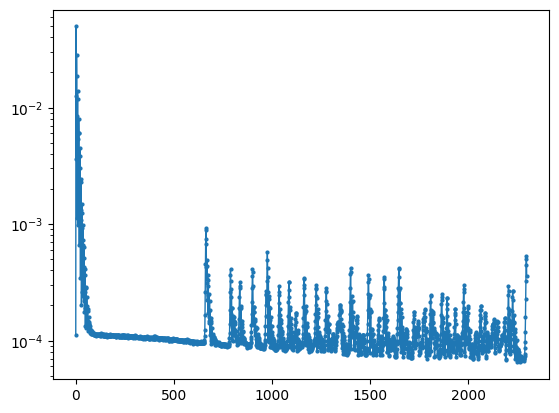

In [30]:
pasitos = np.arange(0,steps)
plt.plot(pasitos, cost_history, marker = "o", linestyle="-", markersize=2, linewidth=1)
plt.yscale("log")
plt.show

Recuperamos el tensor w del archivo.

In [5]:
ruta = os.path.join(os.getcwd(), "costes")
try:
    with open(ruta, "rb") as f:
      while True:
          try:
              checkpoint = np.load(f, allow_pickle = True).item()
              initial = int(checkpoint["iteration"])
              cost = checkpoint["cost"]
              w = jnp.asarray(checkpoint["best_weight"])
              print(w)
              
          except (EOFError):
              break
    print("Tensor recuperado del archivo")
except FileNotFoundError:
    print("Archivo no encontrado")

[[[-0.00244246  0.00396427 -0.00260275]
  [-0.00035355  0.00523801  0.00045638]
  [-0.00114822  0.00629716 -0.00158315]]

 [[ 0.00360462  0.00581042  0.00141085]
  [-0.0033141  -0.00674868  0.00230704]
  [-0.00169526 -0.00719029 -0.00259518]]

 [[-0.00022832  0.00404123 -0.00586756]
  [ 0.00304012  0.00733031  0.00346114]
  [-0.00454913  0.00545672 -0.0025207 ]]]
[[[-0.00244246  0.00983249  0.00140087]
  [-0.00035355  0.01123173 -0.00354277]
  [-0.00114822  0.01226122  0.00279166]]

 [[ 0.00798223  0.0118108   0.00581369]
  [-0.0002477  -0.01259045 -0.00026287]
  [ 0.0026592  -0.01317867  0.0017936 ]]

 [[ 0.00418836  0.01000399 -0.00153461]
  [ 0.00748271  0.01332404  0.00786725]
  [-0.0001896   0.00776932  0.00184007]]]
[[[-0.00244246  0.01567892  0.00335326]
  [-0.00035355  0.01722053 -0.00764731]
  [-0.00114822  0.01815766 -0.00049177]]

 [[ 0.00448501  0.01780991  0.00232585]
  [-0.00393418 -0.0180721  -0.00409896]
  [-0.00072881 -0.01914516 -0.00164467]]

 [[ 0.00077557  0.015897

Aplicamos el Ansatz con los mejores parámetros encontrados a nuestro estado fundamental, dando lugar a la solución |x>. Las amplitudes de dicho estado en cada autoestado serán proporcionales a los valores de la solución real en cada punto.

In [6]:
dev_x = qml.device("lightning.qubit", wires=n_qubits)

@qml.set_shots(n_shots)
@qml.qnode(dev_x, interface="autograd")
def prepare_and_sample(weights):
  variational_block(weights)
  #return qml.sample()
  return(qml.probs(wires = range(n_qubits))) 


In [ ]:

best_weight = w
q_probs = np.sqrt(prepare_and_sample(best_weight))

La solución variacional está normalizada, al estar codificada en las amplitudes de un estado, y tiene la siguiente forma:

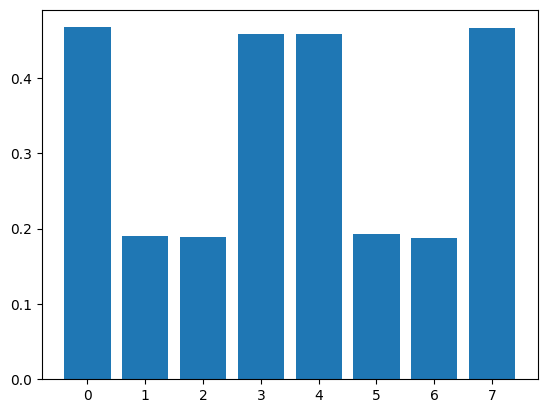

In [9]:
estados = np.arange(0, 2**n_qubits)
plt.bar(estados, q_probs)
plt.show()

Dado que las amplitudes de un estado cuántico son siempre iguales o mayores que cero, este algoritmo no puede dar cuenta de soluciones negativas. Es una limitación evidente de este método.

Calculamos la solución clásica con scipy

In [44]:
from scipy.integrate import solve_bvp
# parámetro ω
omega = 3  # por ejemplo, un valor que sí admite solución exacta

# definimos el sistema de primer orden:
# y1 = y
# y2 = y'
# y1' = y2
# y2' = -omega^2 * y1
def ode(x, y):
    return np.vstack((y[1], -omega**2 * y[0]))

# condiciones de contorno
def bc(ya, yb):
    return np.array([ya[0] - 1, yb[0] - 1])

# malla inicial (gruesa)
x = np.linspace(0, 2, 20)

# estimación inicial: recta entre 1 y 1
y_init = np.vstack((np.ones_like(x), np.zeros_like(x)))

# resolución del problema de contorno
sol = solve_bvp(ode, bc, x, y_init)

if sol.status != 0:
    print("Advertencia: solve_bvp no convergió")

# malla fina para graficar
x_plot = np.linspace(0, 2, 200)
y_plot = sol.sol(x_plot)[0]
y_plot_abs = np.abs(y_plot)



Traducimos la solución cuántica al espacio del problema multiplicando las amplitudes por un escalar.

Representamos las soluciones.

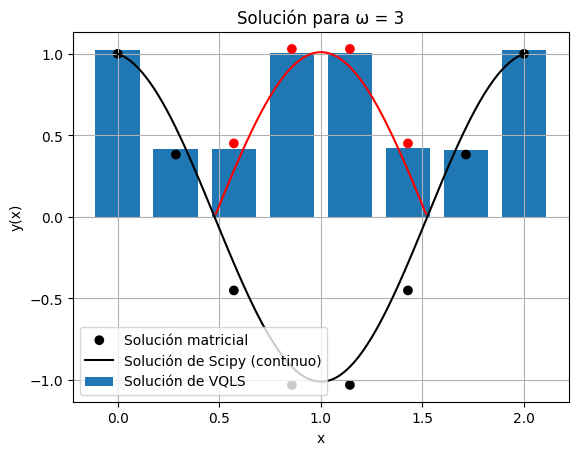

In [54]:
suma = 0
x = np.linspace(start=0, stop=2, num=8)
for i in range(len(x)):
    suma += abs(result[i]) / q_probs[i]
ratio = suma / len(x)
qsol = q_probs * ratio

mask_neg = result < 0

result_abs = np.abs(result)

plt.figure()

plt.bar(x, qsol, align="center", width = 0.22, label="Solución de VQLS")
#plt.scatter(x[~ mask_neg], result_abs[~ mask_neg], marker = "o", linestyle="", color="blue", label="Valores originales")
plt.scatter(x, result, marker = "o", linestyle="", color="black", label="Solución matricial")
plt.scatter(x[mask_neg], result_abs[mask_neg], marker = "o", linestyle="", color="red")

mask2 = y_plot < 0

plt.plot(x_plot, y_plot, color="black", label = "Solución de Scipy (continuo)")
plt.plot(x_plot[mask2], y_plot_abs[mask2], color="red")

plt.xlabel("x")
plt.ylabel("y(x)")
plt.title(f"Solución para ω = {omega}")
plt.grid(True)


#plt.bar(x, q_probs)
plt.grid(linestyle="-")
plt.legend(loc="lower left")
plt.show()

Finalmente, vemos en una gráfica la solución clásica/matricial (puntos y curvas), y la solución de VQLS (las barras).

En rojo, el valor absoluto de la solución clásica.